# 02 · Reliability: how does Component X fail over its life?

**Questions**
1. What share of trucks still have their original Component X at each operating age, and does
   that differ by vehicle specification? (Kaplan–Meier, log-rank tests)
2. Does the hazard rise with age, i.e. does the component *wear out*? (Weibull fit) If yes,
   preventive repair is worth considering at all.
3. Which specs and early-life usage patterns go with a higher hazard? (Cox proportional hazards)
4. **Baseline (b) from CLAUDE.md:** a *fixed-age rule* that picks the urgency class from
   `time_step` alone. Every model in notebooks 03–04 has to beat it.

Data: SCANIA Component X dataset, Swedish National Data Service,
https://doi.org/10.5878/bnh5-ka77, CC BY 4.0.

Reading guide:
- Survival models use the **training** vehicles: one row per vehicle, duration =
  `length_of_study_time_step`, event = `in_study_repair` (0 = right-censored).
- Durations are **time steps** (anonymized operating time), not days.
- **Validation** is used only to tune the fixed-age rule. **Test is not used in this notebook**;
  it is touched once, in notebook 04.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import (CoxPHFitter, ExponentialFitter, KaplanMeierFitter, NelsonAalenFitter,
                       WeibullFitter)
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import viz
from costs import ACTIONS, CLASSES, COST, cost_per_1000, expected_cost_decision
from make_features_sql import COUNTERS

viz.apply_style()
FIGS = ROOT / "docs" / "figures"
con = duckdb.connect(str(ROOT / "data" / "pdm.duckdb"), read_only=True)


def q(sql, *params):
    return con.execute(sql, list(params)).df()


pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)
SPEC_COLS = [f"Spec_{i}" for i in range(8)]
MIN_GROUP = 200   # categories with fewer training vehicles are pooled into "Other"

In [2]:
surv = q('''
    SELECT t.vehicle_id, t.length_of_study_time_step AS T, t.in_study_repair AS E, s.* EXCLUDE (split, vehicle_id)
    FROM train_tte t JOIN specifications s ON s.split = 'train' AND s.vehicle_id = t.vehicle_id
''')
print(f"{len(surv):,} training vehicles, {surv["E"].sum():,} repairs ({surv["E"].mean():.1%}), "
      f"{(1 - surv["E"]).sum():,} censored")

23,550 training vehicles, 2,272 repairs (9.6%), 21,278 censored


## 1. Kaplan–Meier: the share of trucks without a repair, by operating age

Kaplan–Meier is used rather than the crude repair share because 90% of trucks are censored at
different ages (notebook 01). A censored truck counts as "at risk" only until it leaves the
study. The 95% band is the Greenwood confidence interval.

In [3]:
kmf = KaplanMeierFitter().fit(surv["T"], surv["E"], label="all training trucks")
ages = [100, 150, 200, 250, 300, 350, 400, 450]
km_table = pd.DataFrame({
    "S(t): no repair yet": kmf.survival_function_at_times(ages).values,
    "cumulative repair share": 1 - kmf.survival_function_at_times(ages).values,
    "trucks still at risk": [(surv["T"] >= a).sum() for a in ages],
}, index=pd.Index(ages, name="time_step"))
print(f"median time to repair: {kmf.median_survival_time_} "
      "(inf = more than half the trucks are never repaired within the follow-up)")
km_table

median time to repair: inf (inf = more than half the trucks are never repaired within the follow-up)


,S(t): no repair yet,cumulative repair share,trucks still at risk
time_step,,,
100,0.9943,0.0057,23417
150,0.9739,0.0261,18881
200,0.9469,0.0531,13913
250,0.9081,0.0919,9707
300,0.8659,0.1341,6573
350,0.8267,0.1733,3350
400,0.7901,0.2099,1093
450,0.7640,0.2360,287


**Interpretation.** Component X rarely fails early: 99.4% of trucks are repair-free at time step 100. After that, repairs build up steadily: 94.7% are repair-free at 200, 86.6% at 300 and 79.0% at 400. The median time to repair is never reached, because more than half the fleet is still on its original component at the end of follow-up. Beyond about 400 only 1,093 trucks remain at risk (287 at 450), so the tail of the curve is uncertain.

## 2. Weibull fit: is Component X wearing out?

The Weibull model has survival $S(t) = \exp\{-(t/\lambda)^\rho\}$ and hazard
$h(t) = (\rho/\lambda)(t/\lambda)^{\rho-1}$. The **shape** $\rho$ answers the wear-out question:

- $\rho < 1$: the hazard *falls* with age (early failures; preventive replacement would not help),
- $\rho = 1$: constant hazard (exponential; random failures, age carries no information),
- $\rho > 1$: the hazard *rises* with age (wear-out; replacing or inspecting older parts pays off).

It is tested against the exponential model ($\rho = 1$) with a likelihood-ratio test, and checked
visually against Kaplan–Meier and a smoothed Nelson–Aalen hazard.

In [4]:
wf = WeibullFitter().fit(surv["T"], surv["E"])
ef = ExponentialFitter().fit(surv["T"], surv["E"])
lr = 2 * (wf.log_likelihood_ - ef.log_likelihood_)
wb = wf.summary.loc[["lambda_", "rho_"], ["coef", "coef lower 95%", "coef upper 95%"]]
wb.index = ["scale λ", "shape ρ"]
print(f"likelihood-ratio test Weibull vs exponential: LR = {lr:,.1f}, p = {stats.chi2.sf(lr, 1):.2g}")
print(f"AIC Weibull {wf.AIC_:,.0f} vs exponential {ef.AIC_:,.0f}")
h = lambda t: float(wf.hazard_at_times([t]).iloc[0])
print(f"Weibull hazard at t=300 is {h(300) / h(150):.2f}x the hazard at t=150")
wb

likelihood-ratio test Weibull vs exponential: LR = 1,808.0, p = 0
AIC Weibull 38,277 vs exponential 40,083
Weibull hazard at t=300 is 2.64x the hazard at t=150


,coef,coef lower 95%,coef upper 95%
scale λ,695.0903,672.5147,717.6659
shape ρ,2.4000,2.3208,2.4792


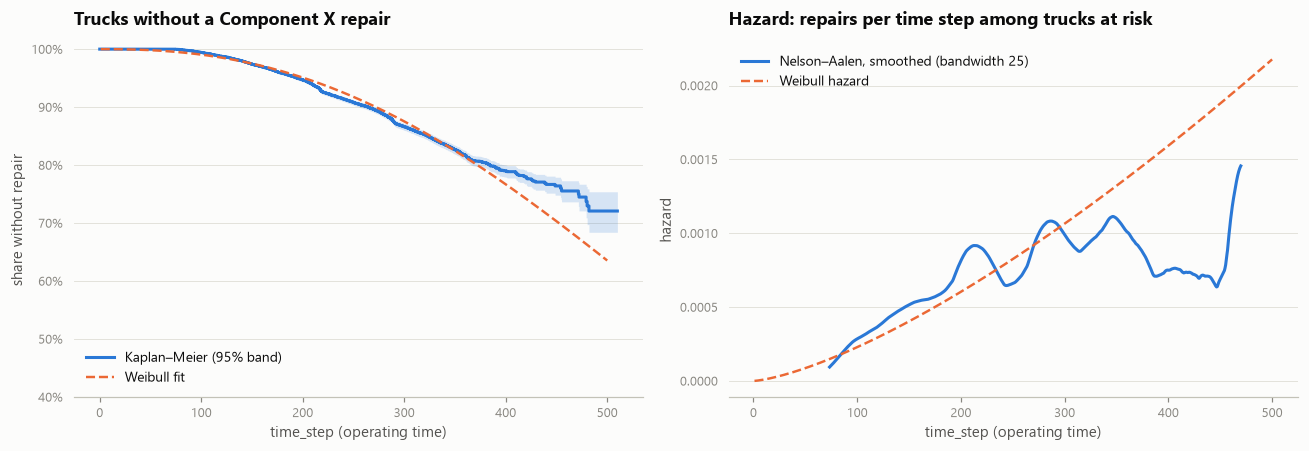

In [5]:
t_grid = np.linspace(1, 500, 300)
naf = NelsonAalenFitter().fit(surv["T"], surv["E"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
sf, ci = kmf.survival_function_, kmf.confidence_interval_
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step="post", color=viz.BLUE, alpha=0.18, lw=0)
ax.step(sf.index, sf.iloc[:, 0], where="post", color=viz.BLUE, label="Kaplan–Meier (95% band)")
ax.plot(t_grid, wf.survival_function_at_times(t_grid), color=viz.ORANGE, lw=1.6, ls="--", label="Weibull fit")
ax.set_ylim(0.4, 1.01)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_title("Trucks without a Component X repair")
ax.set_xlabel("time_step (operating time)")
ax.set_ylabel("share without repair")
ax.legend(loc="lower left")

ax = axes[1]
sm = naf.smoothed_hazard_(bandwidth=25)
sm = sm[(sm.index > 60) & (sm.index < 470)]
ax.plot(sm.index, sm.iloc[:, 0], color=viz.BLUE, label="Nelson–Aalen, smoothed (bandwidth 25)")
ax.plot(t_grid, wf.hazard_at_times(t_grid), color=viz.ORANGE, lw=1.6, ls="--", label="Weibull hazard")
ax.set_title("Hazard: repairs per time step among trucks at risk")
ax.set_xlabel("time_step (operating time)")
ax.set_ylabel("hazard")
ax.legend(loc="upper left")
fig.tight_layout()
viz.save(fig, "02_km_weibull", FIGS)
plt.show()

**Interpretation.** The shape is **ρ = 2.40 (95% CI 2.32–2.48)**, well above 1. The likelihood-ratio test rejects a constant hazard decisively (LR = 1,808), and AIC strongly prefers the Weibull. The hazard therefore **rises with age**: under the Weibull fit it is 2.6× higher at time step 300 than at 150. That is the textbook wear-out pattern, and it is what makes preventive call-ins worth considering at all. The fit tracks Kaplan–Meier closely up to about 350 steps. Beyond that the smoothed Nelson–Aalen hazard flattens while the Weibull keeps rising, so the Weibull overstates failures in the sparse tail, where few trucks remain.

## 3. Kaplan–Meier by specification, with log-rank tests

**Choices.** Within each spec, categories with fewer than 200 training vehicles are pooled
into "Other", so every curve rests on enough trucks (the same pooling is used in the Cox model).
One **multivariate log-rank test per spec** asks whether any of its groups differ. That is 8
tests, so the p-values are corrected with **Holm's method** (controls the family-wise error rate
and is never less powerful than Bonferroni). With 23,550 trucks even small differences become
"significant", so the size of the gap (the repair share by t = 300 per group) is reported next to
the p-value.

In [6]:
def pooled(col):
    counts = surv[col].value_counts()
    keep = counts[counts >= MIN_GROUP].index
    return surv[col].where(surv[col].isin(keep), "Other")


for col in SPEC_COLS:
    surv[f"{col}_g"] = pooled(col)

rows = []
for col in SPEC_COLS:
    g = surv[f"{col}_g"]
    test = multivariate_logrank_test(surv["T"], g, surv["E"])
    by_group = {k: 1 - KaplanMeierFitter().fit(surv["T"][g == k], surv["E"][g == k]).survival_function_at_times(300).iloc[0]
                for k in g.unique()}
    rows.append({"spec": col, "groups": g.nunique(), "chi2": test.test_statistic,
                 "df": g.nunique() - 1, "p_raw": test.p_value,
                 "repair_by_300_min": min(by_group.values()), "repair_by_300_max": max(by_group.values()),
                 "lowest_group": min(by_group, key=by_group.get), "highest_group": max(by_group, key=by_group.get)})
logrank = pd.DataFrame(rows).set_index("spec")
logrank["p_holm"] = multipletests(logrank.p_raw, method="holm")[1]
logrank["significant_5pct"] = logrank.p_holm < 0.05
logrank.sort_values("chi2", ascending=False)

,groups,chi2,df,p_raw,repair_by_300_min,repair_by_300_max,lowest_group,highest_group,p_holm,significant_5pct
spec,,,,,,,,,,
Spec_7,9,425.3371,8,0.0000,0.0243,0.2782,Cat8,Cat7,0.0000,True
Spec_2,9,268.9699,8,0.0000,0.0265,0.3059,Cat12,Cat5,0.0000,True
Spec_1,17,115.4148,16,0.0000,0.0378,0.1885,Cat16,Cat17,0.0000,True
Spec_6,7,108.7069,6,0.0000,0.0526,0.1946,Other,Cat2,0.0000,True
Spec_3,4,96.5883,3,0.0000,0.0693,0.1634,Cat3,Cat1,0.0000,True
Spec_0,3,65.6131,2,0.0000,0.0852,0.1434,Other,Cat0,0.0000,True
Spec_4,2,47.6057,1,0.0000,0.1320,0.2298,Cat0,Cat1,0.0000,True
Spec_5,5,4.3492,4,0.3608,0.1240,0.1434,Cat2,Cat1,0.3608,False


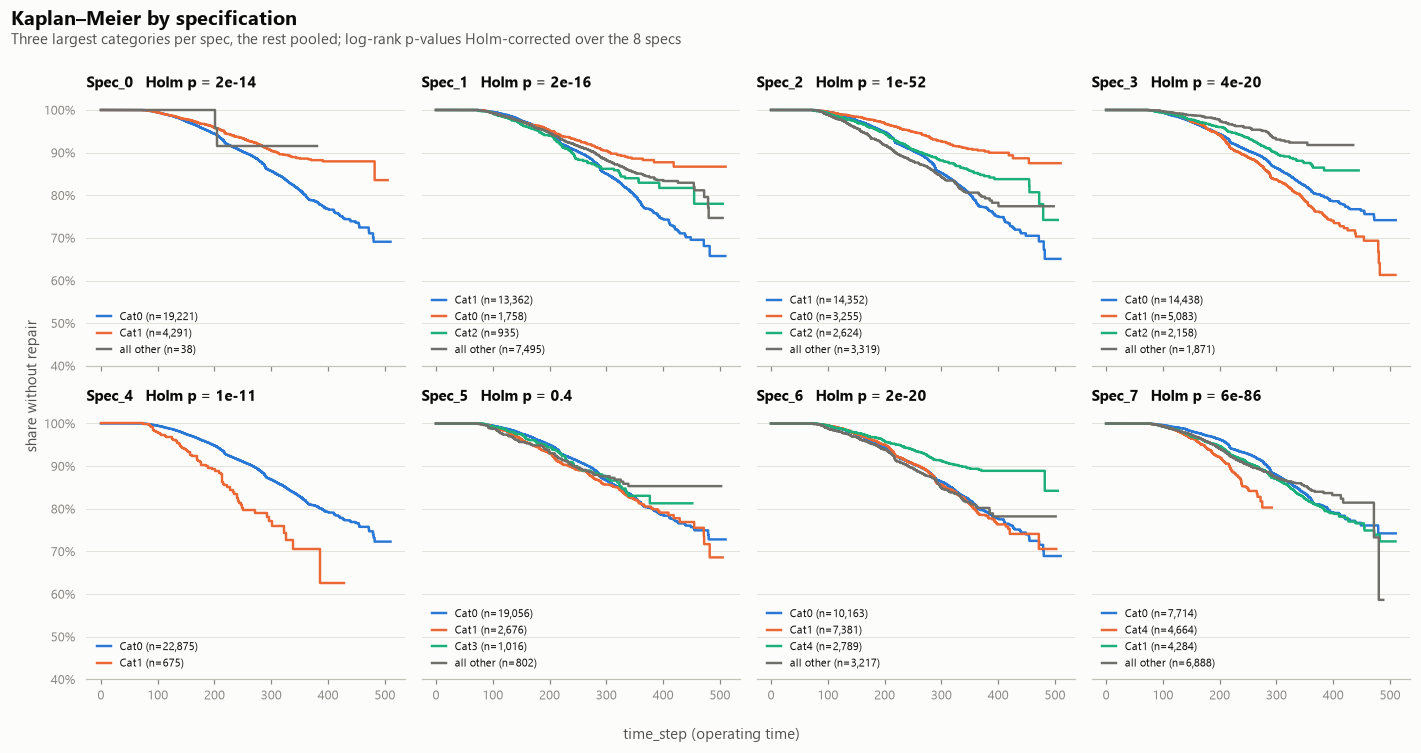

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6), sharex=True, sharey=True)
palette = [viz.BLUE, viz.ORANGE, viz.AQUA]
for ax, col in zip(axes.flat, SPEC_COLS):
    g = surv[f"{col}_g"]
    named = [k for k in g.value_counts().index if k != "Other"][:3]
    rest = ~g.isin(named)
    series = [(k, g == k, palette[i]) for i, k in enumerate(named)]
    if rest.any():
        series.append(("all other", rest, viz.GREY_DARK))
    for label, mask, color in series:
        kf = KaplanMeierFitter().fit(surv["T"][mask], surv["E"][mask])
        s = kf.survival_function_
        ax.step(s.index, s.iloc[:, 0], where="post", color=color, lw=1.6,
                label=f"{label} (n={mask.sum():,})")
    p = logrank.loc[col, "p_holm"]
    ax.set_title(f"{col}   Holm p = {p:.1g}" if p >= 1e-300 else f"{col}   Holm p < 1e-300", fontsize=10)
    ax.legend(loc="lower left", fontsize=7.5, handlelength=1.2)
    ax.yaxis.set_major_formatter(viz.PCT)
ax.set_ylim(0.4, 1.01)
fig.supxlabel("time_step (operating time)", fontsize=9.5, color=viz.INK2)
fig.supylabel("share without repair", fontsize=9.5, color=viz.INK2)
viz.suptitle(fig, "Kaplan–Meier by specification",
             "Three largest categories per spec, the rest pooled; log-rank p-values Holm-corrected over the 8 specs")
fig.tight_layout()
viz.save(fig, "02_km_by_spec", FIGS)
plt.show()

**Interpretation.** Seven of the eight specs show a difference in survival after Holm correction (all corrected p < 1e-10). Only **Spec_5** does not (corrected p = 0.36). The largest gaps are in **Spec_7** (χ² = 425; repaired by time step 300: from 2.4% in Cat8 to 27.8% in Cat7) and **Spec_2** (χ² = 269; from 2.7% in Cat12 to 30.6% in Cat5). Spec_4's small Cat1 group (675 trucks) also fails clearly faster than Cat0. Specs can be correlated with each other and with usage, so these one-at-a-time tests can double-count. The Cox model below adjusts for all specs at once.

## 4. Cox proportional hazards: specs and early-life usage

**Early-life usage rates, without look-ahead.** A truck's usage *before* its repair would leak the
outcome if measured over its whole life (a truck repaired at 100 has a shorter life to average
over). So usage is measured in a fixed **early window, up to time_step 60** (a *landmark*). No truck is
repaired before 73.4 and none is censored before 121 (notebook 01), so every truck is still at
risk at the landmark and the window is the same for all of them.

For each counter, the early rate = (value at the last readout ≤ 60 − value at the first readout)
/ (time between them). Trucks whose early readouts span fewer than 10 time steps, or that have a
missing counter at either end, are left out (counted below).

**Transform.** Counter rates are heavily skewed and a few go slightly negative (rare decreases in
cumulative counters), so each rate is clipped at 0, log-transformed (`log1p`) and standardized.
A hazard ratio (HR) is then *per 1 standard deviation of log usage rate*.

**Specs** enter as indicator variables, with the largest category of each spec as reference and
small categories pooled into "Other" (as in section 3). A small ridge penalty (0.01) keeps the
estimates stable where categories of different specs overlap heavily; it barely moves the HRs.

In [8]:
LANDMARK, MIN_SPAN = 60, 10
cols = ", ".join(f'(l."{c}_0" - f."{c}_0") / (e.t1 - e.t0) AS rate_{c}' for c in COUNTERS)
early = q(f'''
    WITH w AS (SELECT * FROM readouts WHERE split = 'train' AND time_step <= {LANDMARK}),
    e AS (SELECT vehicle_id, min(time_step) AS t0, max(time_step) AS t1, count(*) AS n FROM w GROUP BY 1)
    SELECT e.vehicle_id, e.n AS early_readouts, e.t1 - e.t0 AS early_span, {cols}
    FROM e JOIN w f ON f.vehicle_id = e.vehicle_id AND f.time_step = e.t0
           JOIN w l ON l.vehicle_id = e.vehicle_id AND l.time_step = e.t1
''')
rate_cols = [f"rate_{c}" for c in COUNTERS]
cox_base = surv.merge(early, on="vehicle_id", how="left")
ok = (cox_base.early_span >= MIN_SPAN) & cox_base[rate_cols].notna().all(axis=1)
print(f"trucks with usable early-life rates: {ok.sum():,} of {len(cox_base):,}; "
      f"excluded {(~ok).sum():,} (repair share among excluded {cox_base["E"][~ok].mean():.1%} "
      f"vs {cox_base["E"][ok].mean():.1%} kept)")
cox_df = cox_base[ok].copy()
for c in rate_cols:
    x = np.log1p(cox_df[c].clip(lower=0))
    cox_df[c.replace("rate_", "usage_")] = (x - x.mean()) / x.std()
usage_cols = [c.replace("rate_", "usage_") for c in rate_cols]
corr = cox_df[usage_cols].corr().where(~np.eye(len(usage_cols), dtype=bool))
print(f"largest absolute correlation between usage rates: {corr.abs().max().max():.2f}")
cox_df[["early_readouts", "early_span"]].describe(percentiles=[0.1, 0.5, 0.9]).T

trucks with usable early-life rates: 22,568 of 23,550; excluded 982 (repair share among excluded 4.9% vs 9.9% kept)
largest absolute correlation between usage rates: 0.96


,count,mean,std,min,10%,50%,90%,max
early_readouts,"22,568.0000",10.9914,5.6869,2.0000,4.0000,11.0000,16.0000,66.0000
early_span,"22,568.0000",48.3862,8.9075,10.0000,36.4000,50.8000,56.8000,60.0000


In [9]:
dummies = []
for col in SPEC_COLS:
    g = cox_df[f"{col}_g"]
    ref = g.value_counts().index[0]
    d = pd.get_dummies(g, prefix=col, dtype=float).drop(columns=f"{col}_{ref}")
    dummies.append(d)
X = pd.concat([cox_df[["T", "E"] + usage_cols]] + dummies, axis=1)
X = X.loc[:, X.std() > 0]
cph = CoxPHFitter(penalizer=0.01).fit(X, duration_col="T", event_col="E")
summ = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
summ.columns = ["HR", "HR_low", "HR_high", "p"]
summ["p_holm"] = multipletests(summ.p, method="holm")[1]
print(f"{X.shape[1] - 2} covariates, concordance (training) = {cph.concordance_index_:.3f}")
display(summ.loc[usage_cols].sort_values("HR", ascending=False))
summ.drop(index=usage_cols).assign(dist=lambda d: np.log(d.HR).abs()).sort_values(
    "dist", ascending=False).head(10).drop(columns="dist")

56 covariates, concordance (training) = 0.716


,HR,HR_low,HR_high,p,p_holm
covariate,,,,,
usage_427,1.2900,1.1596,1.4351,0.0000,0.0001
usage_835,1.2314,1.1119,1.3638,0.0001,0.0032
usage_309,1.1800,1.1053,1.2597,0.0000,0.0000
usage_666,1.1462,1.0570,1.2428,0.0010,0.0440
usage_171,1.1285,1.0190,1.2498,0.0202,0.8500
usage_837,1.1059,1.0130,1.2072,0.0245,0.9421
usage_370,1.0594,1.0082,1.1131,0.0224,0.8959
usage_100,0.9900,0.9358,1.0474,0.7276,1.0000


,HR,HR_low,HR_high,p,p_holm
covariate,,,,,
Spec_5_Other,0.4443,0.1605,1.2300,0.1184,1.0000
Spec_2_Cat12,0.4886,0.2197,1.0869,0.0791,1.0000
Spec_2_Cat5,1.9529,1.4845,2.5692,0.0000,0.0001
Spec_2_Cat6,1.8918,1.2354,2.8970,0.0034,0.1480
Spec_1_Cat14,0.5448,0.3705,0.8010,0.0020,0.0908
Spec_4_Cat1,1.8265,1.3452,2.4800,0.0001,0.0056
Spec_7_Cat6,1.7107,1.3684,2.1387,0.0000,0.0001
Spec_1_Cat16,0.5869,0.3044,1.1317,0.1117,1.0000
Spec_7_Cat4,1.6502,1.4492,1.8791,0.0000,0.0000


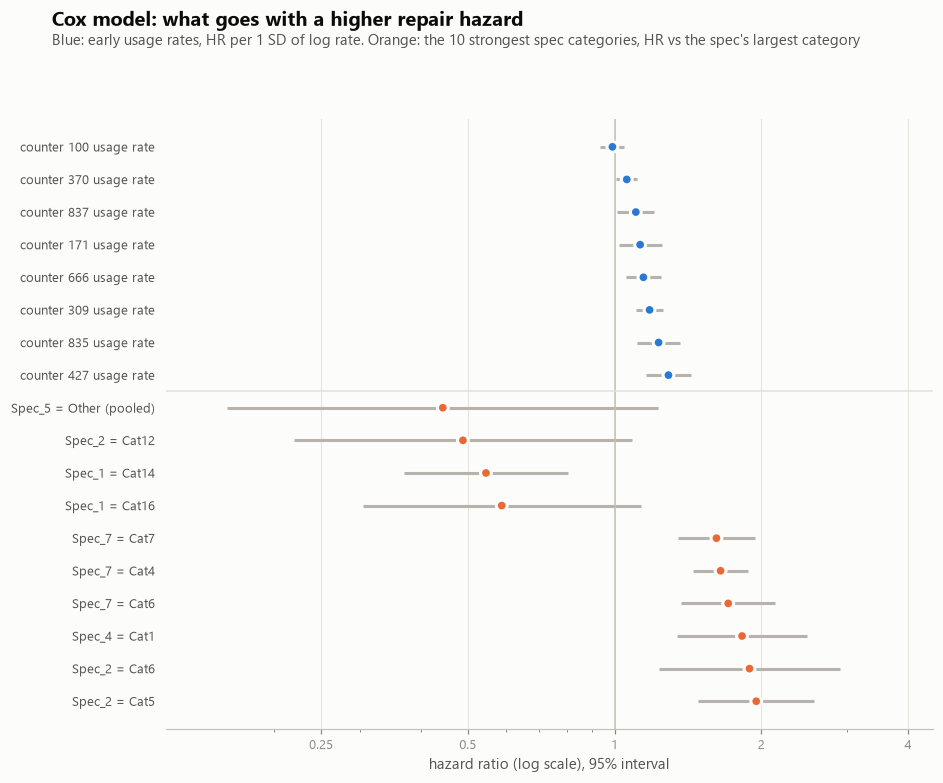

In [10]:
spec_top = summ.drop(index=usage_cols).assign(dist=lambda d: np.log(d.HR).abs()).nlargest(10, "dist")
plot = pd.concat([summ.loc[usage_cols].sort_values("HR"), spec_top.drop(columns="dist").sort_values("HR")])
fig, ax = plt.subplots(figsize=(9, 7.2))
y = np.arange(len(plot))[::-1]
is_usage = plot.index.isin(usage_cols)
labels = [i.replace("usage_", "counter ") + " usage rate" if u
          else i.replace("_Cat", " = Cat").replace("_Other", " = Other (pooled)")
          for i, u in zip(plot.index, is_usage)]
ax.hlines(y, plot.HR_low, plot.HR_high, color=viz.GREY_LIGHT, lw=2)
ax.scatter(plot.HR, y, s=50, zorder=3, edgecolor=viz.SURFACE, lw=2,
           color=[viz.BLUE if u else viz.ORANGE for u in is_usage])
ax.axvline(1, color=viz.AXIS, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_xlim(0.12, 4.5)
ax.set_yticks(y, labels)
ax.tick_params(axis="y", labelsize=8.5, colors=viz.INK2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.axhline(y[is_usage.sum() - 1] - 0.5, color=viz.GRID, lw=1)
ax.set_xlabel("hazard ratio (log scale), 95% interval")
viz.suptitle(fig, "Cox model: what goes with a higher repair hazard",
             "Blue: early usage rates, HR per 1 SD of log rate. Orange: the 10 strongest spec categories, "
             "HR vs the spec's largest category")
viz.save(fig, "02_cox_hazard_ratios", FIGS)
plt.show()

**Interpretation.** 22,568 trucks have usable early-life rates. The 982 left out (an early window under 10 steps, or a missing counter) have a lower repair share (4.9% vs 9.9%), so the model slightly under-represents trucks with sparse early data. Holding specs fixed, **heavier early use goes with a higher hazard**. Four counters stay significant after Holm correction: counter 427 (HR 1.29 per SD, 95% CI 1.16–1.44), counter 835 (1.23), counter 309 (1.18) and counter 666 (1.15). Counters 171, 837 and 370 are only nominally significant, and counter 100 shows no effect. The usage rates are strongly correlated (up to 0.96), so the credit split between individual counters is unstable. The robust message is the joint one, which matches notebook 01: trucks that are used harder fail sooner. Among specs, the risky categories carry HRs of about 1.6–2.0 after adjustment (Spec_2 Cat5 1.95, Spec_4 Cat1 1.83, Spec_7 Cat6/Cat4/Cat7 1.62–1.71); small categories have wide intervals. The training concordance is 0.716. That is optimistic because it is measured on the fitted data, but it shows that specs plus early usage rank trucks' risk well beyond chance.

### 4b. Checking proportional hazards

Cox assumes each covariate multiplies the hazard by the same factor at every age. Two checks:
1. **Scaled Schoenfeld residual test** (`proportional_hazard_test`, rank time transform): a small
   p-value means the effect drifts with age. Holm-corrected across covariates; with this many trucks
   the test flags even small drifts, so magnitude is judged visually.
2. **Log–log plot** for the two strongest usage rates: $\log(-\log S(t))$ against $\log t$ for
   trucks in each tertile of the rate. Under proportional hazards the curves are roughly parallel.

In [11]:
ph = proportional_hazard_test(cph, X, time_transform="rank").summary[["test_statistic", "p"]]
ph["p_holm"] = multipletests(ph.p, method="holm")[1]
print(f"covariates flagged at 5% after Holm: {(ph.p_holm < 0.05).sum()} of {len(ph)}")
ph.sort_values("test_statistic", ascending=False).head(10)

covariates flagged at 5% after Holm: 0 of 56


,test_statistic,p,p_holm
Spec_7_Cat3,10.0544,0.0015,0.0851
usage_666,9.9187,0.0016,0.0900
Spec_7_Cat7,8.0934,0.0044,0.2399
Spec_5_Cat2,7.4165,0.0065,0.3425
usage_370,7.0904,0.0077,0.4030
Spec_4_Cat1,5.7704,0.0163,0.8312
usage_100,5.7650,0.0163,0.8312
Spec_5_Cat1,4.9162,0.0266,1.0000
Spec_2_Cat3,3.6479,0.0561,1.0000
Spec_6_Cat1,3.0562,0.0804,1.0000


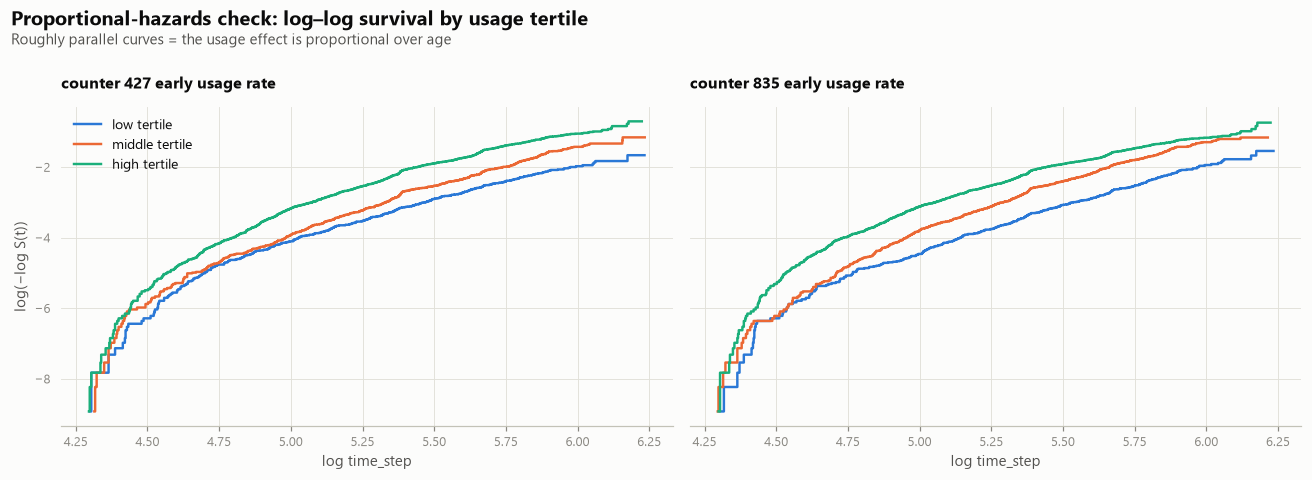

In [12]:
top_usage = summ.loc[usage_cols].assign(dist=lambda d: np.log(d.HR).abs()).nlargest(2, "dist").index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, var in zip(axes, top_usage):
    terc = pd.qcut(cox_df[var], 3, labels=["low", "middle", "high"])
    for lab, color in zip(["low", "middle", "high"], [viz.BLUE, viz.ORANGE, viz.AQUA]):
        m = terc == lab
        s = KaplanMeierFitter().fit(cox_df["T"][m], cox_df["E"][m]).survival_function_.iloc[:, 0]
        s = s[(s < 1) & (s > 0)]
        ax.step(np.log(s.index), np.log(-np.log(s)), where="post", color=color, lw=1.6,
                label=f"{lab} tertile")
    ax.set_title(f"{var.replace('usage_', 'counter ')} early usage rate", fontsize=10.5)
    ax.set_xlabel("log time_step")
    ax.grid(axis="x")
axes[0].set_ylabel("log(−log S(t))")
axes[0].legend(loc="upper left")
viz.suptitle(fig, "Proportional-hazards check: log–log survival by usage tertile",
             "Roughly parallel curves = the usage effect is proportional over age")
fig.tight_layout()
viz.save(fig, "02_ph_check", FIGS)
plt.show()

**Interpretation.** No covariate fails the proportional-hazards test after Holm correction (smallest corrected p = 0.085, for Spec_7 Cat3; usage of counter 666 is next at 0.09). In the log–log plots, the usage tertiles for counters 427 and 835 run roughly parallel, with the high-usage tertile consistently on top. The proportional-hazards assumption is reasonable here, and the hazard ratios are fair summaries over the whole life.

## 5. Fixed-age rule baseline

A planner without any sensor model could still use **age alone**: older trucks get called in
sooner. This is CLAUDE.md's baseline (b): *class chosen from time_step only, thresholds fit on
training survival curves*.

**Step 1 (from the training survival curve).** At age $t$, a truck that has not been repaired yet
has the following conditional class probabilities, read off the Kaplan–Meier curve $S$ with the
half-open windows from CLAUDE.md:

$P(4) = 1 - \frac{S(t+6)}{S(t)}$, $P(3) = \frac{S(t+6) - S(t+12)}{S(t)}$,
$P(2) = \frac{S(t+12) - S(t+24)}{S(t)}$, $P(1) = \frac{S(t+24) - S(t+48)}{S(t)}$,
$P(0) = \frac{S(t+48)}{S(t)}$.

The **KM Bayes rule** picks, at each age, the action with the lowest expected cost under the cost
matrix. It uses no validation data at all.

**Step 2 (tuned on validation).** The baseline proper is a **monotone age rule**: four age
thresholds $a_1 \le a_2 \le a_3 \le a_4$, and a truck aged $t$ gets the most urgent class whose
threshold it has passed. Monotone because the Weibull shape says risk rises with age. Thresholds
are searched on a 5-step grid and chosen to minimise total validation cost, using each validation
truck's age at its last readout (the prediction point). The search is exact: dynamic programming
over the age grid finds the cheapest non-decreasing class sequence.

**Overfitting guard.** Tuning 4 thresholds on 136 validation trucks with a repair flatters the
rule. So the same search is also run in **repeated 5-fold cross-validation over validation
vehicles** (fit on 4 folds, cost on the 5th, 10 repeats). That gives an honest estimate next to
the in-sample number. Test is not used.

In [13]:
val = q('''
    SELECT f.vehicle_id, f.time_step AS age, e.class_label AS y
    FROM vehicle_features f JOIN eval_labels e ON e.split = f.split AND e.vehicle_id = f.vehicle_id
    WHERE f.split = 'validation'
''')
assert len(val) == 5046
y_val = val.y.to_numpy()

# The two naive baselines, checked against docs/PLAN.md (11,375 and 9,823).
naive = {"Run-to-failure (predict 0 for everyone)": cost_per_1000(y_val, np.zeros_like(y_val)),
         "Call every truck in now (predict 4 for everyone)": cost_per_1000(y_val, np.full_like(y_val, 4))}
assert round(naive["Run-to-failure (predict 0 for everyone)"]) == 11375
assert round(naive["Call every truck in now (predict 4 for everyone)"]) == 9823


def km_class_proba(t):
    S = lambda x: kmf.survival_function_at_times(np.asarray(x)).to_numpy()
    s0, s6, s12, s24, s48 = (S(t + d) for d in (0, 6, 12, 24, 48))
    p = np.column_stack([s48, s24 - s48, s12 - s24, s6 - s12, s0 - s6]) / s0[:, None]
    return np.clip(p, 0, 1)


age_grid = np.arange(0, 461, 1.0)
p_grid = km_class_proba(age_grid)
km_rule_grid = expected_cost_decision(p_grid)
pred_km = expected_cost_decision(km_class_proba(val.age.to_numpy()))
print("Age validation trucks are scored at: "
      f"median {val.age.median():.0f}, 10-90% {val.age.quantile(.1):.0f}-{val.age.quantile(.9):.0f}")
print(f"P(repair within 48 steps) from KM: age 100 {1 - p_grid[100, 0]:.1%}, "
      f"age 200 {1 - p_grid[200, 0]:.1%}, age 300 {1 - p_grid[300, 0]:.1%}, age 400 {1 - p_grid[400, 0]:.1%}")
switch = {int(k): float(age_grid[np.argmax(km_rule_grid >= k)]) if (km_rule_grid >= k).any() else None
          for k in range(1, 5)}
print(f"KM Bayes rule: first age at which each class (or a more urgent one) is chosen: {switch}")

Age validation trucks are scored at: median 169, 10-90% 87-317
P(repair within 48 steps) from KM: age 100 1.9%, age 200 3.9%, age 300 4.4%, age 400 3.0%
KM Bayes rule: first age at which each class (or a more urgent one) is chosen: {1: 170.0, 2: 170.0, 3: 175.0, 4: 202.0}


In [14]:
STEP = 5
EDGES = np.arange(0, 520, STEP)


def fit_monotone_age_rule(age, y, allowed=CLASSES):
    '''Exact search: cheapest non-decreasing class per age bin (dynamic programming).'''
    b = np.clip(np.digitize(age, EDGES) - 1, 0, len(EDGES) - 1)
    bin_cost = np.zeros((len(EDGES), 5))
    np.add.at(bin_cost, b, COST[y])            # cost of giving every truck in a bin each class
    big = 1e18
    bin_cost[:, [k for k in CLASSES if k not in allowed]] = big
    best = np.zeros_like(bin_cost)
    arg = np.zeros((len(EDGES), 5), dtype=int)
    best[0] = bin_cost[0]
    for i in range(1, len(EDGES)):
        for k in CLASSES:
            j = int(np.argmin(best[i - 1, :k + 1]))  # ties -> least urgent previous class
            best[i, k], arg[i, k] = bin_cost[i, k] + best[i - 1, j], j
    seq = np.zeros(len(EDGES), dtype=int)
    seq[-1] = int(np.argmin(best[-1]))
    for i in range(len(EDGES) - 1, 0, -1):
        seq[i - 1] = arg[i, seq[i]]
    thresholds = {k: float(EDGES[np.argmax(seq >= k)]) if (seq >= k).any() else None for k in range(1, 5)}
    return seq, thresholds


def apply_age_rule(seq, age):
    return seq[np.clip(np.digitize(age, EDGES) - 1, 0, len(EDGES) - 1)]


def cv_cost(allowed, repeats=10, folds=5):
    costs = []
    for r in range(repeats):
        pred = np.zeros_like(y_val)
        for tr, te in StratifiedKFold(folds, shuffle=True, random_state=r).split(val.age, y_val):
            seq, _ = fit_monotone_age_rule(val.age.to_numpy()[tr], y_val[tr], allowed)
            pred[te] = apply_age_rule(seq, val.age.to_numpy()[te])
        costs.append(cost_per_1000(y_val, pred))
    return np.mean(costs), np.std(costs)


BANDS = np.array([0, 50, 100, 150, 200, 250, 300, 350, 1e9])


def fit_band_rule(age, y):
    '''Unconstrained: the cheapest class in each 50-step age band (any direction).'''
    b = np.digitize(age, BANDS) - 1
    rule = np.full(len(BANDS) - 1, 4)           # empty band -> call in (the overall best)
    for i in range(len(BANDS) - 1):
        if (b == i).any():
            rule[i] = int(COST[y[b == i]].sum(axis=0).argmin())
    return rule


def cv_band(repeats=10, folds=5):
    costs = []
    for r in range(repeats):
        pred = np.zeros_like(y_val)
        for tr, te in StratifiedKFold(folds, shuffle=True, random_state=r).split(val.age, y_val):
            rule = fit_band_rule(val.age.to_numpy()[tr], y_val[tr])
            pred[te] = rule[np.digitize(val.age.to_numpy()[te], BANDS) - 1]
        costs.append(cost_per_1000(y_val, pred))
    return np.mean(costs), np.std(costs)


band_rule = fit_band_rule(val.age.to_numpy(), y_val)
pred_band = band_rule[np.digitize(val.age.to_numpy(), BANDS) - 1]
cv_bands = cv_band()

seq_full, thr_full = fit_monotone_age_rule(val.age.to_numpy(), y_val)
pred_full = apply_age_rule(seq_full, val.age.to_numpy())
seq_one, thr_one = fit_monotone_age_rule(val.age.to_numpy(), y_val, allowed=[0, 4])
pred_one = apply_age_rule(seq_one, val.age.to_numpy())
cv_full, cv_one = cv_cost(CLASSES), cv_cost([0, 4])

policies = pd.DataFrame([
    {"policy": k, "tuned_on_validation": "no", "cost_per_1000_validation": v, "cv_estimate": np.nan}
    for k, v in naive.items()] + [
    {"policy": "KM Bayes rule (age only, no tuning)", "tuned_on_validation": "no",
     "cost_per_1000_validation": cost_per_1000(y_val, pred_km), "cv_estimate": np.nan},
    {"policy": "Fixed-age rule, 1 threshold (call in now above age a)", "tuned_on_validation": "yes",
     "cost_per_1000_validation": cost_per_1000(y_val, pred_one), "cv_estimate": cv_one[0]},
    {"policy": "Fixed-age rule, 4 thresholds (baseline b)", "tuned_on_validation": "yes",
     "cost_per_1000_validation": cost_per_1000(y_val, pred_full), "cv_estimate": cv_full[0]},
    {"policy": "Age bands, any direction (best class per 50-step band)", "tuned_on_validation": "yes",
     "cost_per_1000_validation": cost_per_1000(y_val, pred_band), "cv_estimate": cv_bands[0]},
]).set_index("policy")
band_names = [f"{int(a)}–{int(b) if b < 1e9 else '…'}" for a, b in zip(BANDS[:-1], BANDS[1:])]
print("age-band rule (class per age band): " + ", ".join(f"{n}: {int(k)}" for n, k in zip(band_names, band_rule)))
print(f"tuned thresholds (age from which class >= k is chosen): {thr_full}")
print(f"1-threshold rule: call in now from age {thr_one[4]}")
print(f"CV spread (sd over repeats): 4 thresholds {cv_full[1]:,.0f}, 1 threshold {cv_one[1]:,.0f}")
pd.set_option("display.float_format", "{:,.0f}".format)
policies

age-band rule (class per age band): 0–50: 0, 50–100: 0, 100–150: 4, 150–200: 4, 200–250: 4, 250–300: 0, 300–350: 0, 350–…: 0
tuned thresholds (age from which class >= k is chosen): {1: 65.0, 2: 65.0, 3: 65.0, 4: 65.0}
1-threshold rule: call in now from age 65.0
CV spread (sd over repeats): 4 thresholds 95, 1 threshold 109


,tuned_on_validation,cost_per_1000_validation,cv_estimate
policy,,,
Run-to-failure (predict 0 for everyone),no,"11,375",NaN
Call every truck in now (predict 4 for everyone),no,"9,823",NaN
"KM Bayes rule (age only, no tuning)",no,"12,130",NaN
"Fixed-age rule, 1 threshold (call in now above age a)",yes,"9,702","10,030"
"Fixed-age rule, 4 thresholds (baseline b)",yes,"9,702","10,028"
"Age bands, any direction (best class per 50-step band)",yes,"8,109","8,354"


Why does the wear-out rule (older = more urgent) not beat calling everyone in, while an age-band
rule that may point either way does? The validation trucks answer it: the share with a repair due
within 48 steps (class 1–4) by age at the prediction point, next to what the training
Kaplan–Meier curve predicts for that age.

In [15]:
from sklearn.metrics import roc_auc_score

AGE_BINS = [0, 50, 100, 150, 200, 250, 300, 350, 500]
val["age_bin"] = pd.cut(val.age, AGE_BINS, right=False)
val["km_risk48"] = 1 - km_class_proba(val.age.to_numpy())[:, 0]
by_age = val.assign(due=(val.y > 0).astype(int), cls4=(val.y == 4).astype(int)).groupby("age_bin", observed=True).agg(
    trucks=("y", "size"), due_within_48=("due", "sum"), observed_share=("due", "mean"),
    class4_share=("cls4", "mean"), km_predicted_share=("km_risk48", "mean"))
print(f"AUC of age for 'repair due within 48 steps' on validation: {roc_auc_score(val.y > 0, val.age):.3f}")
pd.set_option("display.float_format", "{:,.3f}".format)
by_age

AUC of age for 'repair due within 48 steps' on validation: 0.430


,trucks,due_within_48,observed_share,class4_share,km_predicted_share
age_bin,,,,,
"[0, 50)",14,0,0.000,0.000,0.002
"[50, 100)",984,23,0.023,0.011,0.015
"[100, 150)",1083,45,0.042,0.022,0.024
"[150, 200)",824,25,0.030,0.019,0.034
"[200, 250)",722,29,0.040,0.025,0.037
"[250, 300)",688,6,0.009,0.004,0.046
"[300, 350)",491,6,0.012,0.008,0.047
"[350, 500)",240,2,0.008,0.000,0.037


**Checking the explanation on training data.** If the falling pattern comes from the
*one-random-cut-per-truck* design rather than from the trucks, the same sampling applied to
training trucks should reproduce it. Below, one readout per training vehicle is drawn at random
(hash-ordered, 5 seeds pooled; readouts with an unknown class are left out), and the share with a
repair due within 48 steps is tabulated by age, as for validation.

In [16]:
train_cut = q(f'''
    WITH s AS (SELECT range AS seed FROM range(5)),
    r AS (SELECT s.seed, l.time_step AS age, l.class_label AS y, l.length_of_study_time_step AS T,
                 row_number() OVER (PARTITION BY s.seed, l.vehicle_id
                                    ORDER BY hash(l.vehicle_id, l.time_step, s.seed)) AS rn
          FROM train_readout_labels l CROSS JOIN s)
    SELECT seed, age, y, T FROM r WHERE rn = 1 AND y IS NOT NULL
''')
train_cut["age_bin"] = pd.cut(train_cut.age, AGE_BINS, right=False)
cmp = pd.DataFrame({
    "train_random_cut_share_due": train_cut.assign(d=train_cut.y > 0).groupby("age_bin", observed=True).d.mean(),
    "validation_share_due": by_age.observed_share,
    "training_KM_predicted": by_age.km_predicted_share,
})
print(f"AUC of age, training random cuts: {roc_auc_score(train_cut.y > 0, train_cut.age):.3f}")
due = train_cut[train_cut.y > 0]
print(f"median repair time of trucks whose random cut is due: {due['T'].median():.0f} "
      f"vs all repaired trucks: {surv.loc[surv['E'] == 1, 'T'].median():.0f}")
cmp

AUC of age, training random cuts: 0.721
median repair time of trucks whose random cut is due: 173 vs all repaired trucks: 208


,train_random_cut_share_due,validation_share_due,training_KM_predicted
age_bin,,,
"[0, 50)",0.003,0.000,0.002
"[50, 100)",0.026,0.023,0.015
"[100, 150)",0.050,0.042,0.024
"[150, 200)",0.064,0.030,0.034
"[200, 250)",0.066,0.040,0.037
"[250, 300)",0.072,0.009,0.046
"[300, 350)",0.084,0.012,0.047
"[350, 500)",0.080,0.008,0.037


In [17]:
calls = pd.crosstab(pd.Series(y_val, name="actual class"),
                    pd.Series(pred_full, name="fixed-age rule (4 thresholds)")).reindex(columns=CLASSES, fill_value=0)
calls

fixed-age rule (4 thresholds),0,1,2,3,4
actual class,,,,,
0,61,0,0,0,4849
1,0,0,0,0,16
2,0,0,0,0,14
3,0,0,0,0,30
4,0,0,0,0,76


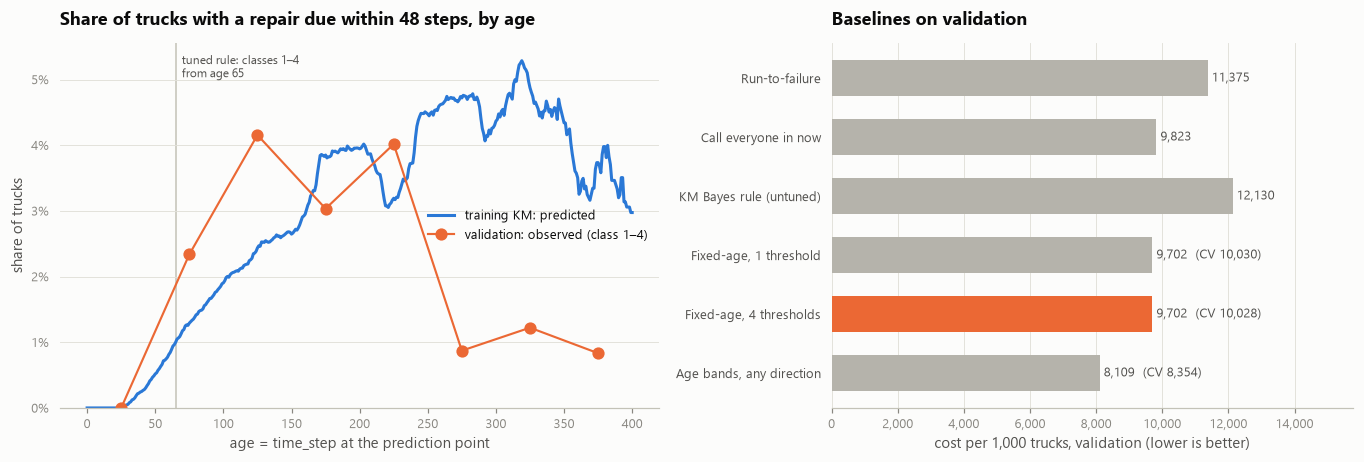

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
risk48 = 1 - p_grid[:, 0]
shown = age_grid <= 400            # beyond ~400 fewer than 1,100 training trucks are at risk
ax.plot(age_grid[shown], risk48[shown], color=viz.BLUE, label="training KM: predicted")
mid = [(iv.left + min(iv.right, 400)) / 2 for iv in by_age.index]
ax.plot(mid, by_age.observed_share, color=viz.ORANGE, marker="o", markersize=7, lw=1.4,
        label="validation: observed (class 1–4)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
by_value = {}
for k, a in thr_full.items():
    if a is not None:
        by_value.setdefault(a, []).append(k)
for a, ks in by_value.items():
    ax.axvline(a, color=viz.AXIS, lw=1, zorder=0)
    lab = f"class {ks[0]}" if len(ks) == 1 else f"classes {ks[0]}–{ks[-1]}"
    ax.annotate(f"tuned rule: {lab}\nfrom age {a:.0f}", (a, 0.97), xycoords=("data", "axes fraction"),
                xytext=(4, 0), textcoords="offset points", fontsize=8, color=viz.INK2, va="top")
ax.set_ylim(0, None)
ax.set_title("Share of trucks with a repair due within 48 steps, by age")
ax.set_xlabel("age = time_step at the prediction point")
ax.set_ylabel("share of trucks")
ax.legend(loc="center right", fontsize=8.5)

ax = axes[1]
pol = policies["cost_per_1000_validation"].iloc[::-1]
short = {"Run-to-failure (predict 0 for everyone)": "Run-to-failure",
         "Call every truck in now (predict 4 for everyone)": "Call everyone in now",
         "KM Bayes rule (age only, no tuning)": "KM Bayes rule (untuned)",
         "Fixed-age rule, 1 threshold (call in now above age a)": "Fixed-age, 1 threshold",
         "Fixed-age rule, 4 thresholds (baseline b)": "Fixed-age, 4 thresholds",
         "Age bands, any direction (best class per 50-step band)": "Age bands, any direction"}
colors = [viz.ORANGE if "4 thresholds" in p else viz.GREY_LIGHT for p in pol.index]
ax.barh(range(len(pol)), pol.values, color=colors, height=0.62)
for i, (p, v) in enumerate(pol.items()):
    cvv = policies.loc[p, "cv_estimate"]
    txt = f"{v:,.0f}" + (f"  (CV {cvv:,.0f})" if pd.notna(cvv) else "")
    ax.text(v + 120, i, txt, va="center", fontsize=8.5, color=viz.INK2)
ax.set_yticks(range(len(pol)), [short[p] for p in pol.index])
ax.tick_params(axis="y", colors=viz.INK2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, pol.max() * 1.3)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("cost per 1,000 trucks, validation (lower is better)")
ax.set_title("Baselines on validation")
fig.tight_layout()
viz.save(fig, "02_fixed_age_rule", FIGS)
plt.show()

**Interpretation.** This is the surprising part of the notebook.

- **The untuned KM Bayes rule loses money** (12,130 per 1,000 trucks, worse than run-to-failure). It takes no action below age 170 and calls trucks in from about 202. But on validation, young trucks are *more* often due than Kaplan–Meier predicts (aged 100–150: 4.2% vs 2.4%), and old trucks are much *less* often due (aged 250 and over: about 1% vs 4–5%).
- **The tuned wear-out rule collapses to "call in every truck older than 65"** (all four thresholds at 65). That is almost the call-everyone policy: 9,702 per 1,000 trucks in-sample and **10,028 in cross-validation**, so out of sample it is *no better than calling everyone in* (9,823).
- **Validation's age pattern runs against wear-out.** The AUC of age for "repair due within 48 steps" is 0.43 on validation, and the due share falls from 3–4% at ages 100–250 to about 1% beyond 250. The same one-random-cut sampling on *training* trucks gives the opposite (AUC 0.72; the due share *rises* to 7–8% beyond 250). So the one-random-cut sampling is **not** the explanation. Validation trucks that are old at their cut point are genuinely rarely due. The data cannot tell us why; SOURCES.md notes that repair rates were perturbed and that validation/test were built by truncation, so the cause probably lies in how those splits were constructed. Test is built the same way, so the pattern probably carries over, but test is not inspected here.
- **An age rule that may point either way does find signal:** call in trucks aged 100–250 and leave the rest gives 8,109 (CV 8,354). It is the best age-only policy on validation, but it is learned from validation alone and contradicts the training survival curves.

**Which one is baseline (b)?** CLAUDE.md defines it as a rule fitted from the training survival curves, so baseline (b) is the **monotone fixed-age rule: 9,702 per 1,000 trucks on validation (CV 10,028)**. The age-band rule is recorded as a stricter, validation-tuned *age-only bar* (8,109), because the models in notebooks 03–04 are also tuned on validation and could pick up the same pattern through `time_step`.

In [19]:
# Small table for later notebooks / Power BI: the baselines on validation.
out = policies.reset_index()
out["thresholds"] = ""
out.loc[out.policy.str.contains("4 thresholds"), "thresholds"] = str(thr_full)
out.loc[out.policy.str.contains("1 threshold"), "thresholds"] = str(thr_one)
out.round(1).to_csv(ROOT / "data" / "processed" / "baselines_validation.csv", index=False)
pd.DataFrame({"age_from": EDGES, "class": seq_full}).to_csv(
    ROOT / "data" / "processed" / "fixed_age_rule.csv", index=False)
print("wrote data/processed/baselines_validation.csv and fixed_age_rule.csv")

wrote data/processed/baselines_validation.csv and fixed_age_rule.csv


## 6. What this means for notebooks 03 and 04

1. **Component X wears out.** Weibull shape ρ = 2.40 (95% CI 2.32–2.48); the hazard at time step 300 is 2.6× the hazard at 150; 13% of trucks are repaired by 300 and 21% by 400. Preventive call-ins make sense in principle: the question is *which* trucks, not whether.

2. **Specs and early-life usage separate high-risk from low-risk trucks, with proportional effects.** Spec_7 and Spec_2 give the largest survival gaps (repaired by 300: 2–31% depending on category). In the Cox model, risky spec categories carry HRs of 1.6–2.0, and heavier early use of counters 427, 835, 309 and 666 adds 15–29% hazard per SD. The concordance is 0.72, and proportional hazards hold. Notebook 03 should therefore include specs (with rare categories pooled) and usage rates, and can expect a useful risk ranking.

3. **Age alone cannot beat calling everyone in, and validation's age pattern contradicts training.** Baseline (b), the fixed-age rule, costs **9,702 per 1,000 trucks on validation (CV 10,028)**, against 9,823 for calling everyone in and 11,375 for run-to-failure. On validation, older trucks are *less* often due (AUC of age 0.43); the same sampling on training gives 0.72 the other way. A model trained on training readouts will learn "older = riskier" and be **miscalibrated for old trucks on validation**. Notebook 03 must check calibration *by age* on validation, recalibrate there if needed, and beat both the fixed-age rule (9,702) and the stricter age-band bar (8,109; CV 8,354).

In [20]:
con.close()